## 2. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

np.random.seed(42)

## 3. Load the real-world economics dataset

In [2]:
# Load the US Macroeconomic Dataset
data = sm.datasets.macrodata.load_pandas().data

print("Dataset shape:", data.shape)
data.head()

Dataset shape: (203, 14)


,year,quarter,realgdp,realcons,realinv,realgovt,realdpi,cpi,m1,tbilrate,unemp,pop,infl,realint
0,1959.0,1.0,2710.349,1707.4,286.898,470.045,1886.9,28.98,139.7,2.82,5.8,177.146,0.00,0.00
1,1959.0,2.0,2778.801,1733.7,310.859,481.301,1919.7,29.15,141.7,3.08,5.1,177.830,2.34,0.74
2,1959.0,3.0,2775.488,1751.8,289.226,491.260,1916.4,29.35,140.5,3.82,5.3,178.657,2.74,1.09
3,1959.0,4.0,2785.204,1753.7,299.356,484.052,1931.3,29.37,140.0,4.33,5.6,179.386,0.27,4.06
4,1960.0,1.0,2847.699,1770.5,331.722,462.199,1955.5,29.54,139.6,3.50,5.2,180.007,2.31,1.19


## 4. Select and prepare economic variables

In [3]:
# Calculate GDP growth as percentage log growth
data["gdp_growth"] = np.log(data["realgdp"]).diff() * 100

# Select three economic variables
economic_data = data[["gdp_growth", "infl", "unemp"]].dropna()

print("Observations:", economic_data.shape[0])
economic_data.head()

Observations: 202


,gdp_growth,infl,unemp
1,2.494213,2.34,5.1
2,-0.119295,2.74,5.3
3,0.349453,0.27,5.6
4,2.219018,2.31,5.2
5,-0.468455,0.14,5.2


In [4]:
# Standardize the variables so that they are on a comparable scale
X = economic_data.values

X_mean = X.mean(axis=0)
X_std = X.std(axis=0)
X_scaled = (X - X_mean) / X_std

n, d = X_scaled.shape

print("Number of observations:", n)
print("Number of features:", d)

Number of observations: 202
Number of features: 3


## 5. Define the multivariate Gaussian log-density

The log-density is used instead of the direct density to reduce numerical underflow.

In [5]:
def log_gaussian_pdf(X, mean, covariance):
    d = X.shape[1]
    diff = X - mean

    sign, log_det = np.linalg.slogdet(covariance)

    if sign <= 0:
        raise ValueError("Covariance matrix must be positive definite.")

    inverse = np.linalg.inv(covariance)
    exponent = np.sum((diff @ inverse) * diff, axis=1)

    return -0.5 * (d * np.log(2 * np.pi) + log_det + exponent)

## 6. Initialize GMM parameters

In [6]:
K = 3  # Number of Gaussian components

# Select K observations as initial means
random_indices = np.random.choice(n, K, replace=False)
means = X_scaled[random_indices].copy()

# Start with the same covariance matrix for each component
global_covariance = np.cov(X_scaled, rowvar=False)
covariances = np.array([
    global_covariance + 1e-6 * np.eye(d)
    for _ in range(K)
])

# Equal initial mixing weights
weights = np.ones(K) / K

print("Initial means:\n", means)
print("\nInitial weights:", weights)

Initial means:
 [[ 0.52445006 -0.0990192   3.09541274]
 [ 0.59563293 -1.06471222 -0.0583784 ]
 [ 0.03545868 -1.04002997 -1.49815261]]

Initial weights: [0.33333333 0.33333333 0.33333333]


## 7. E-step: calculate responsibilities

In [7]:
def expectation(X, means, covariances, weights):
    n = X.shape[0]
    K = len(weights)

    log_prob = np.zeros((n, K))

    for k in range(K):
        log_prob[:, k] = (
            np.log(weights[k]) +
            log_gaussian_pdf(X, means[k], covariances[k])
        )

    # Stable normalization using the log-sum-exp idea
    maximum = np.max(log_prob, axis=1, keepdims=True)
    probabilities = np.exp(log_prob - maximum)

    responsibilities = probabilities / probabilities.sum(axis=1, keepdims=True)

    return responsibilities

## 8. M-step: update parameters

In [8]:
def maximization(X, responsibilities):
    n, d = X.shape
    K = responsibilities.shape[1]

    Nk = responsibilities.sum(axis=0)

    new_weights = Nk / n
    new_means = np.zeros((K, d))
    new_covariances = np.zeros((K, d, d))

    for k in range(K):
        new_means[k] = (
            np.sum(responsibilities[:, k:k+1] * X, axis=0) / Nk[k]
        )

        diff = X - new_means[k]

        new_covariances[k] = (
            (responsibilities[:, k:k+1] * diff).T @ diff
        ) / Nk[k]

        # Small regularization term for numerical stability
        new_covariances[k] += 1e-6 * np.eye(d)

    return new_weights, new_means, new_covariances

## 9. Calculate log-likelihood

In [9]:
def calculate_log_likelihood(X, means, covariances, weights):
    log_prob = np.column_stack([
        np.log(weights[k]) +
        log_gaussian_pdf(X, means[k], covariances[k])
        for k in range(len(weights))
    ])

    maximum = np.max(log_prob, axis=1)

    log_sum = maximum + np.log(
        np.exp(log_prob - maximum[:, None]).sum(axis=1)
    )

    return np.sum(log_sum)

## 10. Run the EM algorithm

In [10]:
max_iterations = 200
tolerance = 1e-6

log_likelihood_history = []

for iteration in range(max_iterations):

    # E-step
    responsibilities = expectation(
        X_scaled, means, covariances, weights
    )

    # M-step
    weights, means, covariances = maximization(
        X_scaled, responsibilities
    )

    # Evaluate the updated model
    log_likelihood = calculate_log_likelihood(
        X_scaled, means, covariances, weights
    )
    log_likelihood_history.append(log_likelihood)

    if iteration > 0:
        change = abs(
            log_likelihood_history[-1] - log_likelihood_history[-2]
        )

        if change < tolerance:
            print("Converged at iteration:", iteration + 1)
            break

print("Final log-likelihood:", log_likelihood_history[-1])
print("Iterations performed:", len(log_likelihood_history))

Converged at iteration: 161
Final log-likelihood: -779.036630754139
Iterations performed: 161


## 11. Plot convergence

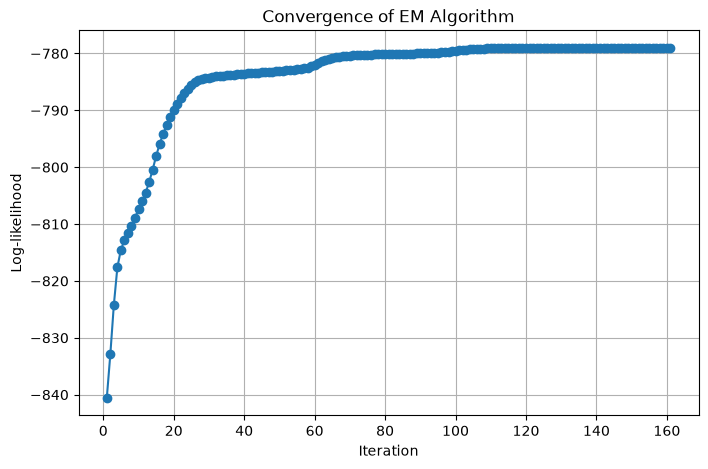

In [11]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(log_likelihood_history) + 1),
         log_likelihood_history, marker="o")
plt.xlabel("Iteration")
plt.ylabel("Log-likelihood")
plt.title("Convergence of EM Algorithm")
plt.grid(True)
plt.show()

## 12. Assign observations to Gaussian components

In [12]:
# Recalculate responsibilities using the final parameters
responsibilities = expectation(
    X_scaled, means, covariances, weights
)

# Assign each observation to the component with highest responsibility
cluster_labels = np.argmax(responsibilities, axis=1)

results = economic_data.copy()
results["Cluster"] = cluster_labels

results.head()

,gdp_growth,infl,unemp,Cluster
1,2.494213,2.34,5.1,2
2,-0.119295,2.74,5.3,2
3,0.349453,0.27,5.6,2
4,2.219018,2.31,5.2,2
5,-0.468455,0.14,5.2,1


## 13. Visualize the clusters

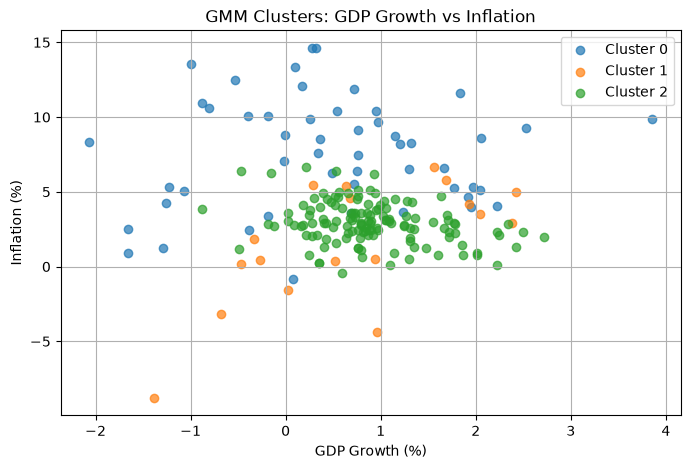

In [13]:
plt.figure(figsize=(8, 5))

for k in range(K):
    cluster_points = results[results["Cluster"] == k]
    plt.scatter(
        cluster_points["gdp_growth"],
        cluster_points["infl"],
        label="Cluster " + str(k),
        alpha=0.7
    )

plt.xlabel("GDP Growth (%)")
plt.ylabel("Inflation (%)")
plt.title("GMM Clusters: GDP Growth vs Inflation")
plt.legend()
plt.grid(True)
plt.show()

## 14. Interpret the clusters

In [14]:
# Average economic indicators in each cluster
cluster_summary = results.groupby("Cluster")[
    ["gdp_growth", "infl", "unemp"]
].mean()

print("Mean economic indicators by cluster:")
display(cluster_summary)

print("\nNumber of observations in each cluster:")
display(results["Cluster"].value_counts().sort_index())

Mean economic indicators by cluster:


,gdp_growth,infl,unemp
Cluster,,,
0,0.483783,7.593137,7.237255
1,0.718712,1.601667,4.516667
2,0.895512,2.917820,5.551880



Number of observations in each cluster:


Cluster
0     51
1     18
2    133
Name: count, dtype: int64

In [18]:
import plotly.express as px
import plotly.graph_objects as go
import pandas as pd

In [19]:
# Select variables for visualization
plot_data = results[
    ["gdp_growth", "infl", "unemp", "Cluster"]
].copy()

# Convert cluster labels into categorical values
plot_data["Cluster"] = plot_data["Cluster"].astype(str)

plot_data.head()


,gdp_growth,infl,unemp,Cluster
1,2.494213,2.34,5.1,2
2,-0.119295,2.74,5.3,2
3,0.349453,0.27,5.6,2
4,2.219018,2.31,5.2,2
5,-0.468455,0.14,5.2,1


In [20]:
fig = px.scatter_3d(
    plot_data,
    x="gdp_growth",
    y="infl",
    z="unemp",
    color="Cluster",
    title="3D Visualization of GMM Clusters",
    labels={
        "gdp_growth": "GDP Growth (%)",
        "infl": "Inflation (%)",
        "unemp": "Unemployment (%)",
        "Cluster": "GMM Cluster"
    },
    opacity=0.75
)

fig.update_traces(marker=dict(size=5))

fig.update_layout(
    width=1000,
    height=750
)

fig.show()